In [38]:
# Importing all required libraries for data analysis,
# visualisation, clustering and dimensionality reduction.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

print("Libraries imported successfully!")

Libraries imported successfully!


In [39]:
# Loading the Kaggle Online Retail dataset.
# ISO-8859-1 encoding is used because the dataset contains
# some special characters.

df = pd.read_csv("OnlineRetail.csv", encoding="ISO-8859-1")

# Display the first five records
print("First five records:")
display(df.head())

# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display column information and data types
print("\nDataset information:")
df.info()

First five records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


Dataset shape: (541909, 8)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [40]:
# Removing records where CustomerID is missing.

df = df.dropna(subset=['CustomerID'])

# Removing cancelled invoices.
# Cancelled invoice numbers start with 'C'.

df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

# Removing transactions with invalid quantities or prices.

df = df[
    (df['Quantity'] > 0) &
    (df['UnitPrice'] > 0)
]

# Converting CustomerID into integer and then string format.

df['CustomerID'] = df['CustomerID'].astype(int).astype(str)

# Calculating the total purchase amount for each transaction.

df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

# Display cleaned dataset

print("Cleaned dataset:")
display(df.head())

print("Shape after cleaning:", df.shape)

Cleaned dataset:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850,United Kingdom,20.34


Shape after cleaning: (397884, 9)


In [41]:
# Converting InvoiceDate into datetime format.

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Setting the reference date as one day after the last transaction.

reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

# Grouping customer transactions and calculating RFM values.

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
})

# Renaming the columns.

rfm.columns = ['Recency', 'Frequency', 'Monetary']

# Display RFM results.

print("RFM Analysis:")
display(rfm.head())

print("Total customers:", len(rfm))

RFM Analysis:


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


Total customers: 4338


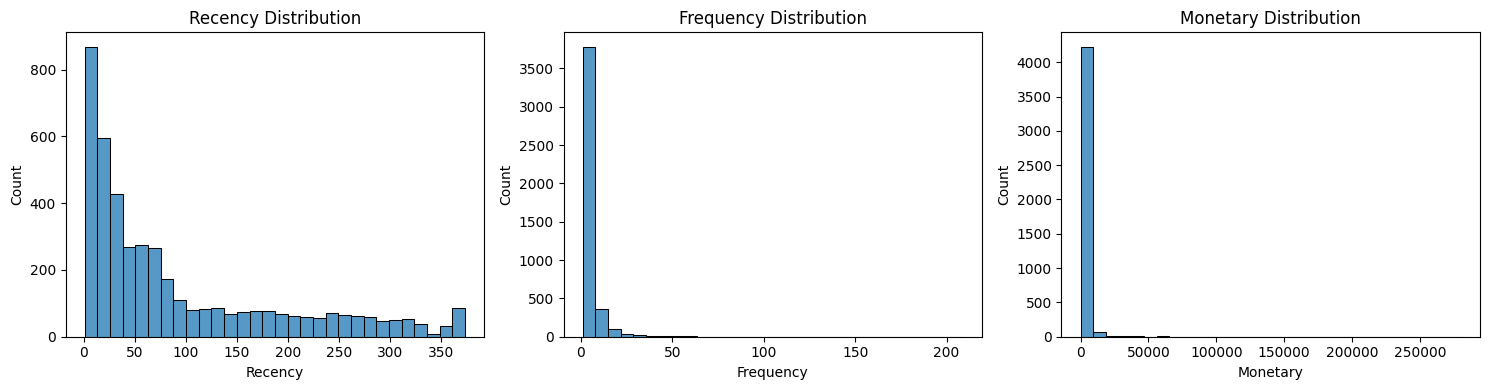

In [42]:
# Creating histograms to understand the distribution
# of Recency, Frequency and Monetary values.

plt.figure(figsize=(15, 4))

# Recency distribution
plt.subplot(1, 3, 1)
sns.histplot(rfm['Recency'], bins=30)
plt.title("Recency Distribution")
plt.xlabel("Recency")

# Frequency distribution
plt.subplot(1, 3, 2)
sns.histplot(rfm['Frequency'], bins=30)
plt.title("Frequency Distribution")
plt.xlabel("Frequency")

# Monetary distribution
plt.subplot(1, 3, 3)
sns.histplot(rfm['Monetary'], bins=30)
plt.title("Monetary Distribution")
plt.xlabel("Monetary")

plt.tight_layout()
plt.show()

In [43]:
# Applying log1p transformation to reduce skewness
# in Frequency and Monetary values.

rfm_log = np.log1p(rfm)

# Applying StandardScaler to bring all features
# onto a comparable scale.

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

# Display first five scaled records.

print("Scaled RFM data:")
print(rfm_scaled[:5])

Scaled RFM data:
[[ 1.46199281 -0.95521426  3.70622476]
 [-2.03873442  1.07442519  1.41184341]
 [ 0.37310424  0.38630445  0.7164889 ]
 [-0.62308592 -0.95521426  0.6987394 ]
 [ 1.42455753 -0.95521426 -0.6189622 ]]


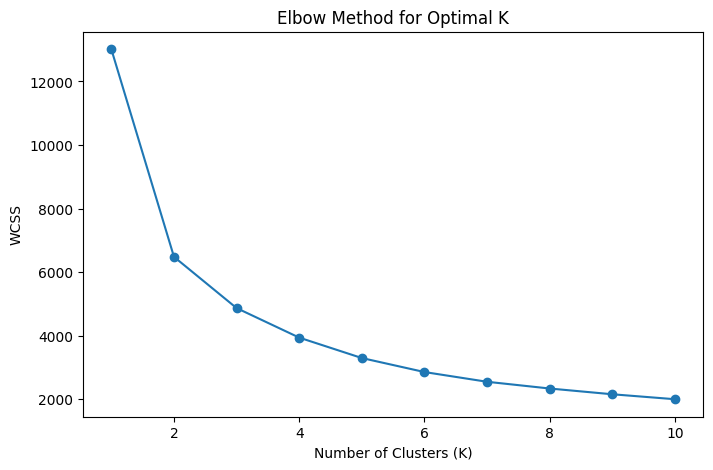

In [44]:
# Calculating WCSS (Within-Cluster Sum of Squares)
# for different values of K.

wcss = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    wcss.append(kmeans.inertia_)

# Plotting the Elbow graph.

plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method for Optimal K")

plt.show()

K = 2 | Silhouette Score = 0.433
K = 3 | Silhouette Score = 0.337
K = 4 | Silhouette Score = 0.337
K = 5 | Silhouette Score = 0.316
K = 6 | Silhouette Score = 0.313
K = 7 | Silhouette Score = 0.31
K = 8 | Silhouette Score = 0.301


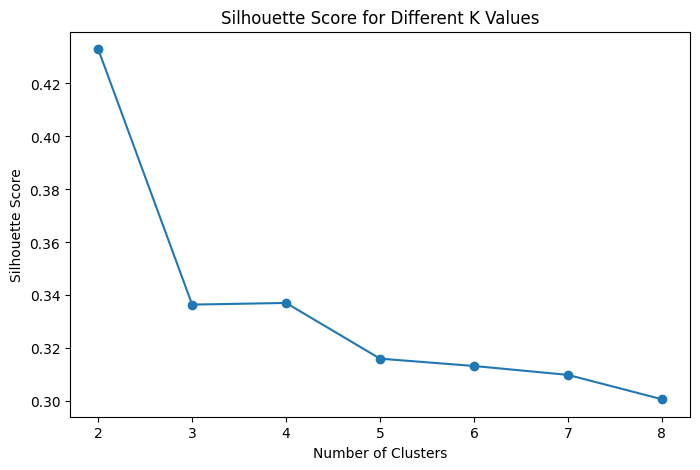

In [45]:
# Calculating Silhouette Score for K values from 2 to 8.
# A higher score generally indicates better-separated clusters.

silhouette_scores = []

for k in range(2, 9):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    score = silhouette_score(rfm_scaled, labels)

    silhouette_scores.append(score)

    print(
        "K =", k,
        "| Silhouette Score =", round(score, 3)
    )

# Plotting silhouette scores for comparison.

plt.figure(figsize=(8, 5))

plt.plot(range(2, 9), silhouette_scores, marker='o')

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")

plt.show()

In [46]:
# Applying K-Means clustering with four clusters.

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Assigning cluster labels to each customer.

rfm['KMeans_Cluster'] = kmeans.fit_predict(rfm_scaled)

# Displaying customer cluster assignments.

print("K-Means clustering results:")
display(rfm.head())

K-Means clustering results:


,Recency,Frequency,Monetary,KMeans_Cluster
CustomerID,,,,
12346,326,1,77183.60,2
12347,2,7,4310.00,1
12348,75,4,1797.24,2
12349,19,1,1757.55,0
12350,310,1,334.40,3


In [47]:
# Grouping customers according to their K-Means cluster.
# Calculating average Recency, Frequency and Monetary values.

cluster_summary = rfm.groupby('KMeans_Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'
}).round(2)

print("K-Means Cluster Summary:")
display(cluster_summary)

K-Means Cluster Summary:


,Recency,Frequency,Monetary
KMeans_Cluster,,,
0,18.12,2.15,551.82
1,12.13,13.71,8074.27
2,71.08,4.08,1802.83
3,182.50,1.32,343.45


In [48]:
# Applying DBSCAN to identify dense customer groups
# and detect noise or outlier customers.

dbscan = DBSCAN(
    eps=0.5,
    min_samples=10
)

# Assigning DBSCAN cluster labels.

rfm['DBSCAN_Cluster'] = dbscan.fit_predict(rfm_scaled)

# Displaying cluster counts.

print("DBSCAN Cluster Distribution:")
print(rfm['DBSCAN_Cluster'].value_counts().sort_index())

# -1 represents noise or outliers.

DBSCAN Cluster Distribution:
DBSCAN_Cluster
-1      79
 0    2780
 1    1479
Name: count, dtype: int64


In [49]:
# Evaluating DBSCAN using Silhouette Score.
# Noise points (-1) are excluded from this calculation.

labels = rfm['DBSCAN_Cluster'].values

# Selecting non-noise customers.

mask = labels != -1

valid_labels = labels[mask]

# Silhouette Score requires at least two clusters
# and fewer clusters than the number of samples.

if len(set(valid_labels)) >= 2 and len(valid_labels) > len(set(valid_labels)):

    score = silhouette_score(
        rfm_scaled[mask],
        valid_labels
    )

    print("DBSCAN Silhouette Score:", round(score, 3))

else:

    print("Not enough non-noise clusters to calculate Silhouette Score.")

# Counting noise points.

print("Number of noise points:", np.sum(labels == -1))

DBSCAN Silhouette Score: 0.294
Number of noise points: 79


In [50]:
# Applying Principal Component Analysis (PCA)
# to reduce the three RFM features into two dimensions.

pca = PCA(n_components=2)

pca_result = pca.fit_transform(rfm_scaled)

# Creating a DataFrame containing PCA values.

pca_df = pd.DataFrame(
    pca_result,
    columns=['PCA1', 'PCA2'],
    index=rfm.index
)

# Adding K-Means cluster labels.

pca_df['Cluster'] = rfm['KMeans_Cluster'].values

# Displaying explained variance.

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print(
    "Total Explained Variance:",
    pca.explained_variance_ratio_.sum()
)

display(pca_df.head())

Explained Variance Ratio:
[0.75102042 0.18759201]
Total Explained Variance: 0.9386124314129813


,PCA1,PCA2,Cluster
CustomerID,,,
12346,0.872658,2.686758,2
12347,2.550260,-0.804427,1
12348,0.475142,0.746121,2
12349,0.145832,-0.460480,0
12350,-1.688990,0.676555,3


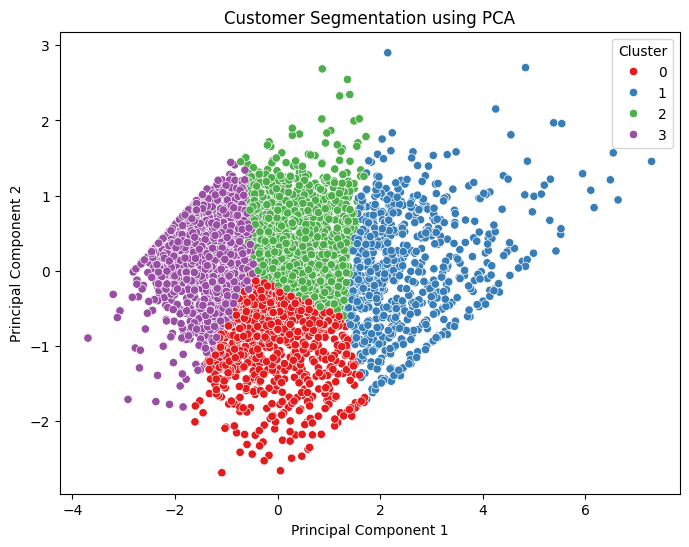

In [51]:
# Plotting customers using the two principal components.
# Different colours represent different K-Means clusters.

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=pca_df,
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='Set1'
)

plt.title("Customer Segmentation using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

In [52]:
# Applying t-SNE to reduce RFM data into two dimensions.
# All customers are included so that the final CSV
# contains t-SNE coordinates for every customer.

tsne = TSNE(
    n_components=2,
    perplexity=min(30, len(rfm_scaled) - 1),
    random_state=42,
    init='pca',
    learning_rate='auto'
)

tsne_result = tsne.fit_transform(rfm_scaled)

# Creating a DataFrame containing t-SNE coordinates.

tsne_df = pd.DataFrame(
    tsne_result,
    columns=['tSNE1', 'tSNE2'],
    index=rfm.index
)

# Adding K-Means cluster labels.

tsne_df['Cluster'] = rfm['KMeans_Cluster'].values

print("t-SNE results:")
display(tsne_df.head())

t-SNE results:


,tSNE1,tSNE2,Cluster
CustomerID,,,
12346,40.178780,24.451754,2
12347,39.480560,-31.787054,1
12348,43.654720,33.243626,2
12349,-10.546079,-25.145607,0
12350,-66.646355,10.141704,3


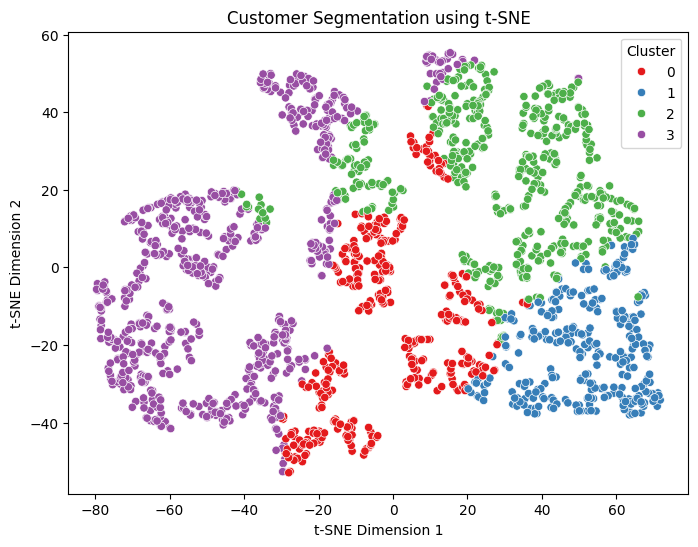

In [53]:
# Plotting the t-SNE results.
# Sampling at most 2000 customers for a clearer graph.

sample_size = min(2000, len(tsne_df))

rng = np.random.RandomState(42)

sample_indices = rng.choice(
    len(tsne_df),
    size=sample_size,
    replace=False
)

tsne_sample = tsne_df.iloc[sample_indices]

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=tsne_sample,
    x='tSNE1',
    y='tSNE2',
    hue='Cluster',
    palette='Set1'
)

plt.title("Customer Segmentation using t-SNE")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")

plt.show()

In [54]:
# Calculating median values of RFM features.

recency_median = rfm['Recency'].median()
frequency_median = rfm['Frequency'].median()
monetary_median = rfm['Monetary'].median()


# Function to assign marketing personas to customers.

def assign_persona(row):

    # High spending but low purchase frequency
    if row['Monetary'] > monetary_median * 3 and \
       row['Frequency'] <= frequency_median:

        return "B2B / Wholesale Outlier"

    # Recent customers with high frequency and spending
    elif row['Recency'] <= recency_median and \
         row['Frequency'] > frequency_median and \
         row['Monetary'] > monetary_median:

        return "Champions / VIPs"

    # Customers who have not purchased recently
    elif row['Recency'] > recency_median:

        return "Hibernating / At-Risk"

    # Recent customers with low purchase frequency
    elif row['Recency'] <= recency_median and \
         row['Frequency'] <= frequency_median:

        return "New Customers"

    else:

        return "Potential Loyalists"


# Applying persona function to every customer.

rfm['Persona'] = rfm.apply(assign_persona, axis=1)

print("Customer Marketing Personas:")
display(rfm[['Recency', 'Frequency', 'Monetary', 'Persona']].head(10))

# Counting customers in each persona.

print("\nPersona Distribution:")
print(rfm['Persona'].value_counts())

Customer Marketing Personas:


,Recency,Frequency,Monetary,Persona
CustomerID,,,,
12346,326,1,77183.60,B2B / Wholesale Outlier
12347,2,7,4310.00,Champions / VIPs
12348,75,4,1797.24,Hibernating / At-Risk
12349,19,1,1757.55,New Customers
12350,310,1,334.40,Hibernating / At-Risk
12352,36,8,2506.04,Champions / VIPs
12353,204,1,89.00,Hibernating / At-Risk
12354,232,1,1079.40,Hibernating / At-Risk
12355,214,1,459.40,Hibernating / At-Risk



Persona Distribution:
Persona
Hibernating / At-Risk      2123
Champions / VIPs           1302
New Customers               723
Potential Loyalists         147
B2B / Wholesale Outlier      43
Name: count, dtype: int64


In [55]:
# Creating a copy of the RFM DataFrame.

final_output = rfm.copy()

# Adding PCA coordinates.

final_output['PCA1'] = pca_result[:, 0]
final_output['PCA2'] = pca_result[:, 1]

# Adding t-SNE coordinates.

final_output['tSNE1'] = tsne_result[:, 0]
final_output['tSNE2'] = tsne_result[:, 1]

# Resetting index to convert CustomerID into a column.

final_output = final_output.reset_index()

# Arranging columns in the required order.

final_output = final_output[
    [
        'CustomerID',
        'Recency',
        'Frequency',
        'Monetary',
        'KMeans_Cluster',
        'DBSCAN_Cluster',
        'PCA1',
        'PCA2',
        'tSNE1',
        'tSNE2',
        'Persona'
    ]
]

# Exporting all customer segmentation results into one CSV file.

final_output.to_csv(
    "Customer_Segmentation_Final_Output.csv",
    index=False
)

# Displaying final results.

print("CSV file created successfully!")

print("\nFinal Customer Segmentation Output:")

display(final_output.head(10))

print("\nTotal customers:", len(final_output))

print("\nTotal columns:", len(final_output.columns))

CSV file created successfully!

Final Customer Segmentation Output:


,CustomerID,Recency,Frequency,Monetary,KMeans_Cluster,DBSCAN_Cluster,PCA1,PCA2,tSNE1,tSNE2,Persona
0,12346,326,1,77183.60,2,-1,0.872658,2.686758,40.178780,24.451754,B2B / Wholesale Outlier
1,12347,2,7,4310.00,1,0,2.550260,-0.804427,39.480560,-31.787054,Champions / VIPs
2,12348,75,4,1797.24,2,0,0.475142,0.746121,43.654720,33.243626,Hibernating / At-Risk
3,12349,19,1,1757.55,0,1,0.145832,-0.460480,-10.546079,-25.145607,New Customers
4,12350,310,1,334.40,3,1,-1.688990,0.676555,-66.646355,10.141704,Hibernating / At-Risk
5,12352,36,8,2506.04,2,0,1.439575,0.636477,56.328876,4.387300,Champions / VIPs
6,12353,204,1,89.00,3,1,-2.153987,-0.066231,-64.555328,-31.800556,Hibernating / At-Risk
7,12354,232,1,1079.40,3,1,-1.023559,0.919003,-45.155464,17.506268,Hibernating / At-Risk
8,12355,214,1,459.40,3,1,-1.397610,0.557738,-53.670479,10.055913,Hibernating / At-Risk
9,12356,23,3,2811.43,2,0,0.925984,0.092258,27.696373,17.452225,Champions / VIPs



Total customers: 4338

Total columns: 11
